
L'objectif de ce notebook est d'analyser les variations du chiffre d'affaires net quotidien des trois points de vente et d'identifier les facteurs associés à ces variations.

L'analyse portera sur le volume de transactions, le panier moyen, les effets calendaires et les différences entre établissements.

Les résultats permettront de caractériser les journées les plus et les moins performantes, de formuler des hypothèses explicatives et d'identifier des pistes d'amélioration de l'activité commerciale.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

performance_quotidienne = pd.read_csv('../data/processed/performance_quotidienne.csv', parse_dates=['Date'])
performance_quotidienne.head()

,Date,Outlet,CA_net,Nb_transactions,Nb_articles,Panier_moyen,Jour_semaine,Mois
0,2025-01-02,SHOP001,1808108.121,82,94,22050.099037,Thursday,1
1,2025-01-02,SHOP002,1116216.221,51,64,21886.592569,Thursday,1
2,2025-01-02,SHOP003,1234234.242,58,66,21279.900724,Thursday,1
3,2025-01-03,SHOP001,2334234.248,101,122,23111.230178,Friday,1
4,2025-01-03,SHOP002,486486.490,26,26,18711.018846,Friday,1


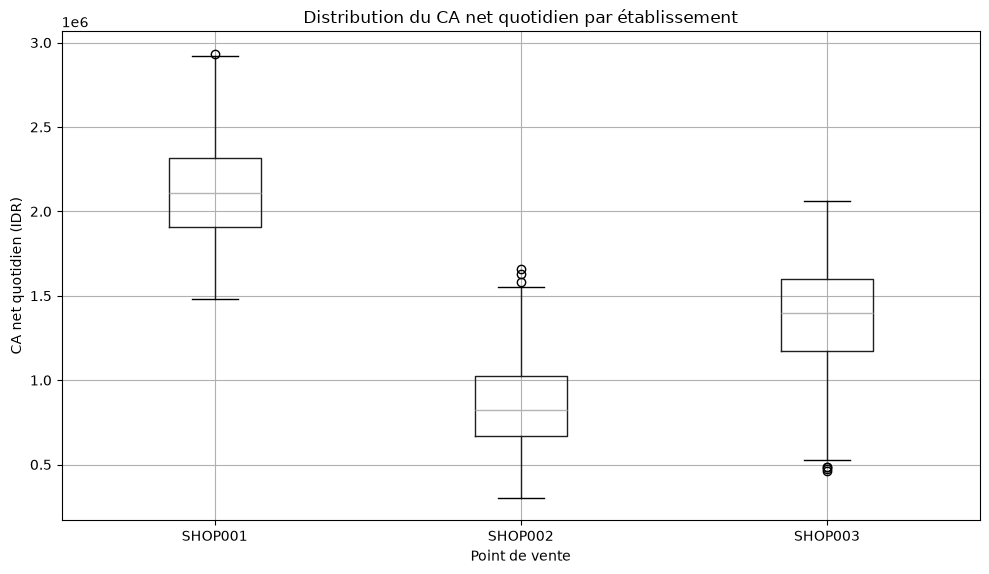

In [36]:
performance_quotidienne.boxplot(column='CA_net', by='Outlet', figsize=(10, 6))
plt.title('Distribution du CA net quotidien par établissement')
plt.suptitle('')
plt.xlabel('Point de vente')
plt.ylabel('CA net quotidien (IDR)')
plt.tight_layout()
plt.show()

Notre boxplot montre des différences importantes dans les niveaux de chiffre d'affaires quotidien. SHOP001 présente la médiane la plus élevée, suivi de SHOP003 puis de SHOP002.
Les trois établissements présentent des fluctuations quotidiennes et quelques valeurs atypiques. Cependant, la comparaison de leur régularité nécessite de tenir compte de leurs niveaux moyens de chiffre d'affaires.

In [37]:
stats_ca = performance_quotidienne.groupby('Outlet')['CA_net'].agg(['mean', 'std'])
stats_ca['CV (%)'] = stats_ca['std'] / stats_ca['mean'] * 100
stats_ca


,mean,std,CV (%)
Outlet,,,
SHOP001,2.133373e+06,319357.647581,14.969611
SHOP002,8.666667e+05,267604.856242,30.877483
SHOP003,1.356333e+06,354539.032490,26.139531



Le calcul du coefficient de variation montre que SHOP001 présente la plus faible dispersion relative de son chiffre d'affaires quotidien (14,97 %), suivi de SHOP003 (26,14 %) et de SHOP002 (30,88 %).

SHOP001 apparaît donc comme l'établissement dont le chiffre d'affaires est le plus régulier relativement à sa moyenne.

À l'inverse, SHOP002 présente la variabilité relative la plus importante, ce qui traduit des fluctuations plus marquées par rapport à son niveau moyen d'activité.

Ces résultats soulèvent la question des facteurs associés à ces variations, notamment le nombre de transactions, le panier moyen et les effets calendaires.

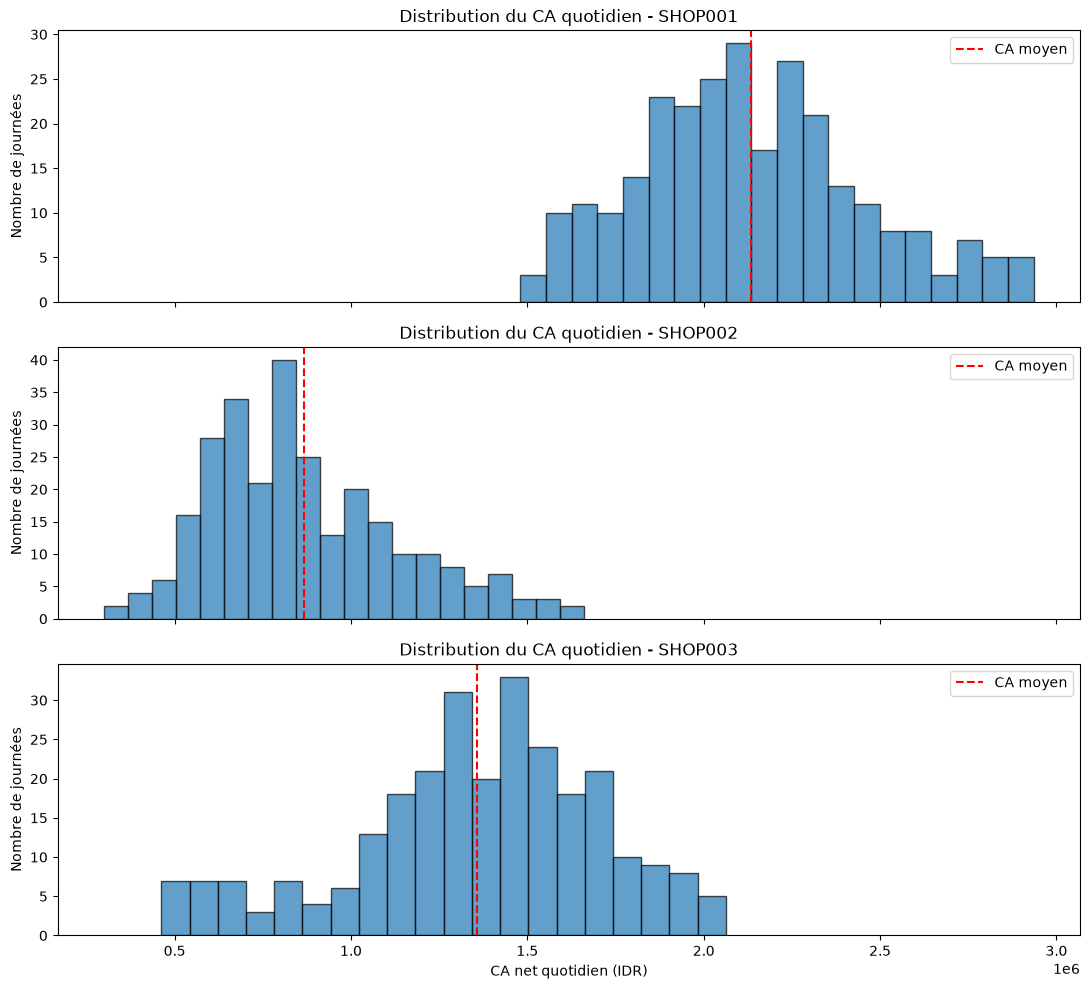

In [38]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

for ax, (shop, data) in zip(axes, performance_quotidienne.groupby('Outlet')):
    ax.hist(data['CA_net'], bins=20, edgecolor='black', alpha=0.7)
    ax.axvline(data['CA_net'].mean(), color='red', linestyle='--', label='CA moyen')
    ax.set_title(f'Distribution du CA quotidien - {shop}')
    ax.set_ylabel('Nombre de journées')
    ax.legend()

axes[-1].set_xlabel('CA net quotidien (IDR)')
plt.tight_layout()
plt.show()

Les histogrammes montrent des différences dans la distribution du chiffre d'affaires quotidien des trois établissements.

SHOP001 présente une distribution relativement concentrée autour de son CA moyen, ce qui confirme sa plus faible variabilité relative.

SHOP002 présente une distribution asymétrique vers les valeurs élevées. Une proportion importante des journées réalise un CA inférieur à la moyenne, tandis que certaines journées particulièrement performantes contribuent à augmenter celle-ci.

SHOP003 présente une distribution plus étalée, avec un ensemble de journées caractérisées par un CA particulièrement faible.

Ces observations confirment les différences de variabilité identifiées précédemment et soulèvent la question des facteurs associés à ces écarts de performance.

Nous chercherons notamment à déterminer dans quelle mesure le volume de transactions, le panier moyen et les effets calendaires permettent d'expliquer ces variations.

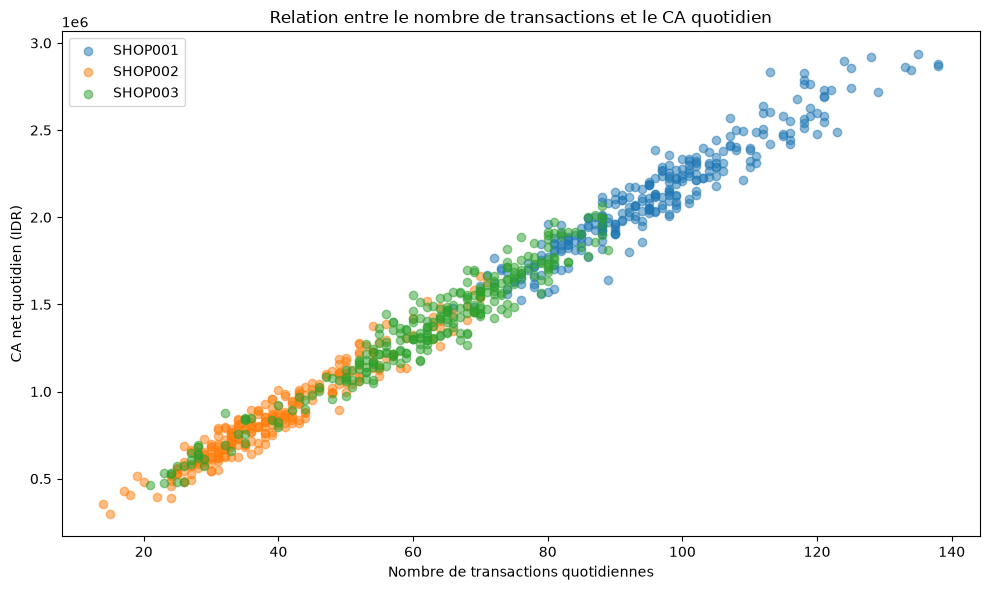

In [39]:
plt.figure(figsize=(10, 6))

for shop, data in performance_quotidienne.groupby('Outlet'):
    plt.scatter(data['Nb_transactions'], data['CA_net'], alpha=0.5, label=shop)

plt.title('Relation entre le nombre de transactions et le CA quotidien')
plt.xlabel('Nombre de transactions quotidiennes')
plt.ylabel('CA net quotidien (IDR)')
plt.legend()
plt.tight_layout()
plt.show()

Le nuage de points met en évidence une relation positive, approximativement linéaire, entre le nombre de transactions quotidiennes et le chiffre d'affaires net des trois établissements.

Les journées enregistrant davantage de transactions sont généralement associées à des chiffres d'affaires plus élevés.

Cette tendance est commune aux trois points de vente. Toutefois, pour un nombre de transactions comparable, des différences de chiffre d'affaires subsistent, suggérant une contribution du panier moyen.

Une analyse quantitative de la corrélation, puis de la contribution respective du volume de transactions et du panier moyen, permettra de préciser ces observations.

In [40]:
performance_quotidienne.groupby('Outlet').apply(lambda x: x['Nb_transactions'].corr(x['CA_net']), include_groups=False)

Outlet
SHOP001    0.955793
SHOP002    0.969506
SHOP003    0.972759
dtype: float64

Les coefficients de corrélation de Pearson sont respectivement de 0,9558 pour SHOP001, 0,9695 pour SHOP002 et 0,9728 pour SHOP003.

Ces résultats confirment une très forte association linéaire positive entre le nombre de transactions et le chiffre d'affaires quotidien pour les trois établissements.

Toutefois, cette relation est en partie structurelle puisque le chiffre d'affaires correspond au produit du nombre de transactions par le panier moyen.

Il est donc nécessaire d'étudier également la variabilité du panier moyen afin de mieux comprendre les composantes des fluctuations quotidiennes du chiffre d'affaires.

In [41]:
stats_panier = performance_quotidienne.groupby('Outlet')['Panier_moyen'].agg(['mean', 'std', 'min', 'median', 'max'])
stats_panier['CV (%)'] = stats_panier['std'] / stats_panier['mean'] * 100
stats_panier

,mean,std,min,median,max,CV (%)
Outlet,,,,,,
SHOP001,22114.173587,975.976744,18443.162404,22138.481281,25081.719062,4.413354
SHOP002,21760.717259,1746.781944,16178.678750,21673.270492,27169.274737,8.027226
SHOP003,22015.367597,1369.255651,18607.068692,22011.744015,27421.171312,6.219545



Les trois établissements présentent des paniers moyens quotidiens relativement proches, compris en moyenne entre 21 761 et 22 114 IDR.

Leurs coefficients de variation sont respectivement de 4,41 % pour SHOP001, 8,03 % pour SHOP002 et 6,22 % pour SHOP003.

Ces valeurs sont nettement inférieures aux coefficients de variation du chiffre d'affaires quotidien, compris entre 14,97 % et 30,88 %.

Ces résultats indiquent que le panier moyen est relativement stable, tandis que le chiffre d'affaires quotidien présente des fluctuations plus importantes.

Combinée aux fortes corrélations précédemment observées entre le nombre de transactions et le CA, cette stabilité suggère que les variations du volume de transactions constituent une composante majeure des fluctuations quotidiennes de l'activité.

Cette hypothèse devra être confirmée par une analyse quantitative de la contribution respective du nombre de transactions et du panier moyen.

In [42]:
stats_transactions = performance_quotidienne.groupby('Outlet')['Nb_transactions'].agg(['mean', 'std'])
stats_transactions['CV (%)'] = stats_transactions['std'] / stats_transactions['mean'] * 100
stats_transactions

,mean,std,CV (%)
Outlet,,,
SHOP001,96.507353,14.132476,14.643937
SHOP002,39.768382,11.619174,29.217114
SHOP003,61.591912,15.528536,25.211973


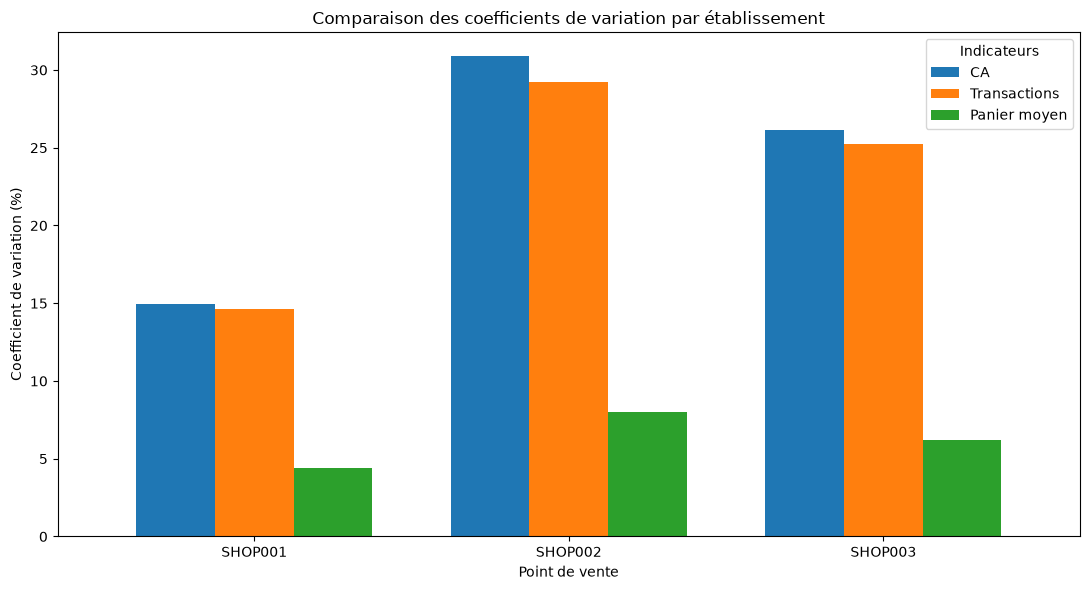

In [43]:
comparaison_cv = pd.DataFrame({'CA': stats_ca['CV (%)'], 'Transactions': stats_transactions['CV (%)'], 'Panier moyen': stats_panier['CV (%)']})

ax = comparaison_cv.plot(kind='bar', figsize=(11, 6), width=0.75)

ax.set_title('Comparaison des coefficients de variation par établissement')
ax.set_xlabel('Point de vente')
ax.set_ylabel('Coefficient de variation (%)')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Indicateurs')

plt.tight_layout()
plt.show()

La comparaison des coefficients de variation met en évidence une forte proximité entre la variabilité du chiffre d'affaires quotidien et celle du nombre de transactions.

Pour SHOP001, ces coefficients sont respectivement de 14,97 % et 14,64 %, contre 30,88 % et 29,22 % pour SHOP002, et 26,14 % et 25,21 % pour SHOP003.

À l'inverse, le panier moyen présente une variabilité relative nettement inférieure, comprise entre 4,41 % et 8,03 %.

Ces résultats, associés aux fortes corrélations observées précédemment, suggèrent que les fluctuations du nombre de transactions constituent la principale composante des variations quotidiennes du chiffre d'affaires.

Cette interprétation reste descriptive et ne permet pas, à elle seule, d'établir une relation causale.

La suite de l'analyse cherchera à identifier les facteurs associés aux variations du volume de transactions.

In [44]:
transactions_semaine = performance_quotidienne.groupby(['Outlet', 'Jour_semaine'])['Nb_transactions'].mean().unstack()
transactions_semaine = transactions_semaine.reindex(columns=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
transactions_semaine

Jour_semaine,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Outlet,,,,,,,
SHOP001,95.205128,97.820513,96.394737,96.358974,94.948718,96.717949,98.102564
SHOP002,39.641026,39.179487,39.289474,41.307692,40.641026,38.743590,39.564103
SHOP003,61.102564,60.205128,62.447368,59.641026,65.153846,59.512821,63.102564


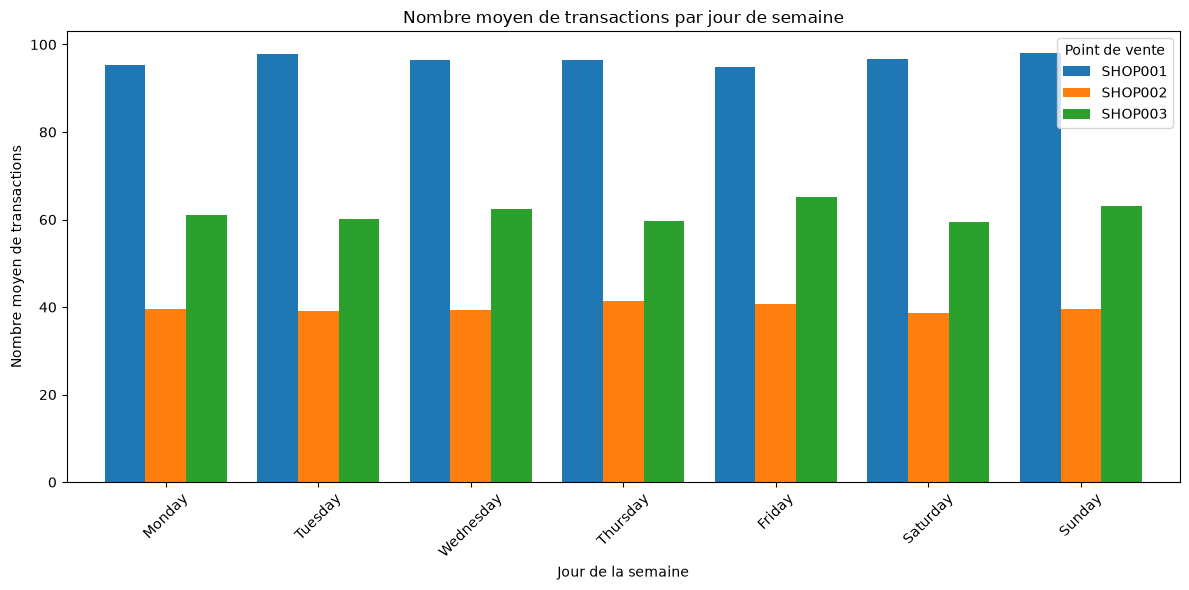

In [45]:
ax = transactions_semaine.T.plot(kind='bar', figsize=(12, 6), width=0.8)

ax.set_title('Nombre moyen de transactions par jour de semaine')
ax.set_xlabel('Jour de la semaine')
ax.set_ylabel('Nombre moyen de transactions')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Point de vente')

plt.tight_layout()
plt.show()

Le graphique met en évidence une relative stabilité du nombre moyen de transactions entre les différents jours de la semaine pour les trois établissements.

SHOP001 enregistre approximativement 95 à 98 transactions quotidiennes, contre 39 à 42 pour SHOP002 et 59 à 65 pour SHOP003.

Les différences observées restent modestes et ne permettent pas d'identifier un jour systématiquement plus performant dans les trois établissements.

Ces résultats suggèrent que le jour de semaine, considéré isolément, ne constitue pas un facteur majeur de différenciation du volume moyen de transactions sur la période étudiée.

Il reste néanmoins nécessaire d'examiner les variations mensuelles afin de déterminer si des effets saisonniers ou des périodes particulières contribuent davantage aux fluctuations de l'activité.

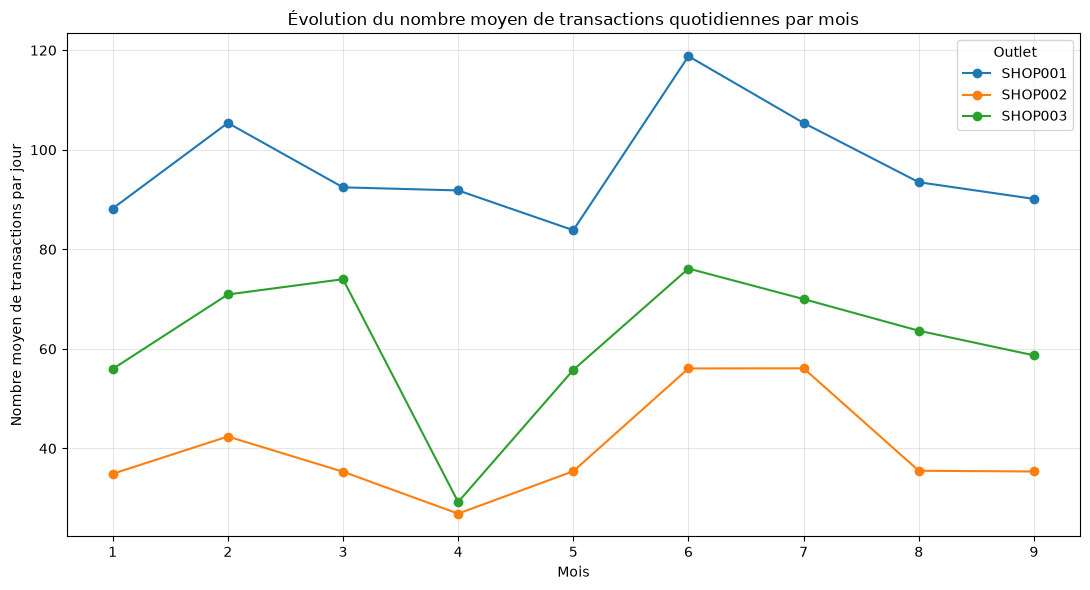

In [46]:
transactions_mensuelles = performance_quotidienne.groupby(['Mois', 'Outlet'])['Nb_transactions'].mean().unstack()
transactions_mensuelles.plot(kind='line', marker='o', figsize=(11, 6))

plt.title('Évolution du nombre moyen de transactions quotidiennes par mois')
plt.xlabel('Mois')
plt.ylabel('Nombre moyen de transactions par jour')
plt.xticks(range(1, 10))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

L'analyse mensuelle met en évidence des fluctuations importantes du volume moyen de transactions quotidiennes dans les trois établissements.

Une baisse d'activité est observée en avril, particulièrement marquée pour SHOP003, dont le nombre moyen de transactions diminue d'environ 61 % par rapport à mars.

À l'inverse, le mois de juin correspond à une période de forte activité pour les trois établissements, suivie d'un ralentissement progressif en août et septembre.

Ces évolutions sont cohérentes avec les variations du chiffre d'affaires identifiées précédemment.

Combinées à la relative stabilité du panier moyen, elles renforcent l'hypothèse selon laquelle les fluctuations du volume de transactions constituent la principale composante des variations quotidiennes du chiffre d'affaires.

Toutefois, les données disponibles ne permettent pas encore d'identifier les causes de ces fluctuations.

In [47]:
#Analyse des tickets : nombre d'articles dans un ticket

transactions = pd.read_csv('../data/raw/Transactions.csv')

distribution_articles = transactions['TotalItem'].value_counts().sort_index()
distribution_articles

TotalItem
1    45667
2     8153
Name: count, dtype: int64

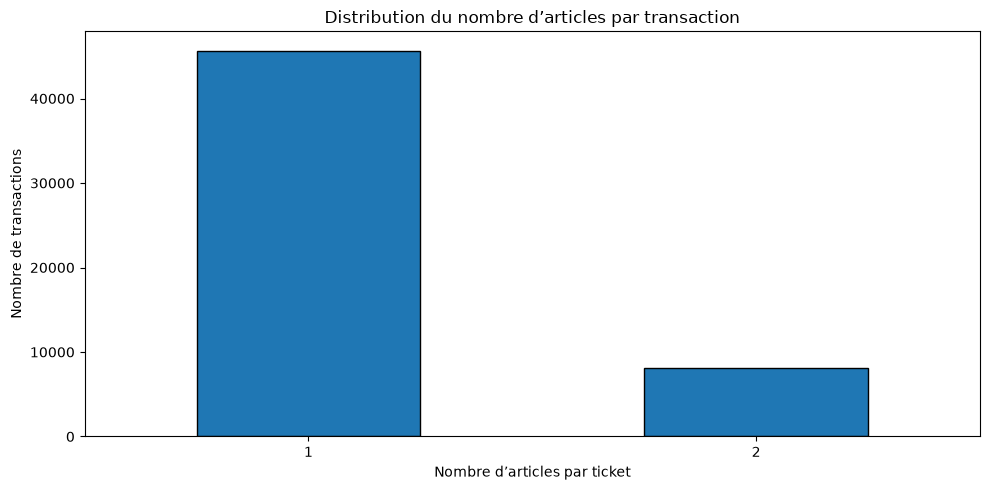

In [48]:
ax = distribution_articles.plot(kind='bar', figsize=(10, 5), edgecolor='black')

ax.set_title('Distribution du nombre d’articles par transaction')
ax.set_xlabel('Nombre d’articles par ticket')
ax.set_ylabel('Nombre de transactions')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [49]:
articles_par_ticket = transactions.groupby('Outlet')['TotalItem'].mean()
articles_par_ticket

Outlet
SHOP001    1.152343
SHOP002    1.144772
SHOP003    1.154480
Name: TotalItem, dtype: float64

In [50]:
comparaison_tickets = transactions.groupby('TotalItem')['NetSales'].agg(['count', 'mean', 'median'])
comparaison_tickets

,count,mean,median
TotalItem,,,
1,45667,18874.670027,20720.721
2,8153,39615.329868,40540.541


le graphique nous montre que les transactions contenant deux articles génèrent en moyenne un montant net plus élevé que celles contenant un seul article.

In [51]:
tickets_deux_articles = transactions.loc[transactions['TotalItem'] == 2, ['ReceiptNumber', 'Outlet', 'Items', 'TotalItem', 'NetSales']]

tickets_deux_articles.head(15)

,ReceiptNumber,Outlet,Items,TotalItem,NetSales
2,SHOP002JAN2500001,SHOP002,"Friendly Coffee (Hot), Shakencano",2,39639.640
3,SHOP002JAN2500002,SHOP002,"BLACK (Arabica), Americano (Hot Arabica)",2,36036.036
4,SHOP002JAN2500003,SHOP002,"WHITE (Arabica), Susu Oat",2,36036.036
16,SHOP003JAN2500002,SHOP003,"Espresso Arabica (On The Rock), Vanilla Latte ...",2,37837.838
20,SHOP001JAN2500009,SHOP001,"Green Thai Tea, WHITE (Arabica)",2,45945.946
21,SHOP003JAN2500005,SHOP003,"Not Tiramisu Latte (Gedhe), Cappuccino (Ice Ho...",2,46846.847
32,SHOP002JAN2500014,SHOP002,"Red Apple, Red Liquid",2,39639.640
33,SHOP001JAN2500014,SHOP001,"Banana Bread (Chocolate), Americano (Ice Arabica)",2,28828.829
36,SHOP003JAN2500007,SHOP003,"BLACK (Arabica), Matcha Espresso",2,40540.541
39,SHOP001JAN2500017,SHOP001,"Jasmine (Ice), Matcha Latte (Ice)",2,40540.541


In [52]:
verification_items = tickets_deux_articles['Items'].str.count(',').value_counts().sort_index()
verification_items

Items
1    8153
Name: count, dtype: int64

In [53]:
tickets_deux_articles = tickets_deux_articles.copy()

tickets_deux_articles['Paire_produits'] = tickets_deux_articles['Items'].str.split(', ').apply(lambda produits: tuple(sorted(produit.strip() for produit in produits)))

frequence_paires = tickets_deux_articles['Paire_produits'].value_counts()

frequence_paires.head(10)

Paire_produits
(Chocolate (Ice), Summer)                                      8
(Butterscotch, Thai Tea)                                       8
(Espresso Arabica (Basic Espresso), Hazelnut Latte (Gedhe))    8
(Candy Latte, Donat Polos)                                     8
(Gula Gula, Hazelnut Latte (Gedhe))                            7
(Apple Pie Latte, Happy Moca (Ice))                            7
(Butterscotch Latte (Gedhe), Extra Shot (Arabica))             7
(Chocolate (Ice), Not Tiramisu Latte)                          7
(Cappuccino (Hot Houseblend), Green Thai Tea)                  7
(Creamy Klepon, Hazelnut Latte)                                7
Name: count, dtype: int64

In [54]:
nombre_paires_uniques = tickets_deux_articles['Paire_produits'].nunique()

nombre_paires_uniques

3687

In [55]:
seuils_ca = performance_quotidienne.groupby('Outlet')['CA_net'].quantile([0.25, 0.75]).unstack()

seuils_ca.columns = ['Q1', 'Q3']

seuils_ca

,Q1,Q3
Outlet,,
SHOP001,1.905405e+06,2.315766e+06
SHOP002,6.671171e+05,1.024550e+06
SHOP003,1.170496e+06,1.600676e+06


In [56]:
performance_classes = performance_quotidienne.merge(seuils_ca, on='Outlet', how='left')

performance_classes['Niveau_CA'] = 'Intermédiaire'

performance_classes.loc[performance_classes['CA_net'] <= performance_classes['Q1'], 'Niveau_CA'] = 'Faible'
performance_classes.loc[performance_classes['CA_net'] >= performance_classes['Q3'], 'Niveau_CA'] = 'Élevé'

In [57]:
transactions_analyse = transactions.copy()
transactions_analyse['Date'] = pd.to_datetime(transactions_analyse['Date'])

transactions_analyse = transactions_analyse.merge(performance_classes[['Date', 'Outlet', 'Niveau_CA']], on=['Date', 'Outlet'], how='left')

transactions_analyse['Ticket_2_articles'] = (transactions_analyse['TotalItem'] == 2).astype(int)

comparaison_proportions = transactions_analyse[transactions_analyse['Niveau_CA'].isin(['Faible', 'Élevé'])].groupby(['Outlet', 'Niveau_CA'])['Ticket_2_articles'].mean().mul(100).unstack()

comparaison_proportions

Niveau_CA,Faible,Élevé
Outlet,,
SHOP001,14.651750,16.139767
SHOP002,11.396469,15.200840
SHOP003,14.735699,16.305566


La proportion de tickets contenant deux articles est plus élevée pendant les journées à fort chiffre d'affaires dans les trois établissements.

Les écarts observés sont de :

- SHOP001 : +1,49 point de pourcentage.
- SHOP002 : +3,80 points de pourcentage.
- SHOP003 : +1,57 point de pourcentage.

SHOP002 présente la différence la plus importante entre journées à faible et à fort CA.

Ces résultats suggèrent que la composition des tickets est associée au niveau de performance quotidienne, en complément du volume de transactions.

Toutefois, cette comparaison reste descriptive. Elle ne permet pas de démontrer une relation causale entre la proportion de tickets à deux articles et l'augmentation du chiffre d'affaires.

Conclusion : 


L'analyse des performances commerciales des trois établissements met en évidence des différences importantes de chiffre d'affaires et de stabilité de l'activité.

Les résultats montrent que les variations du CA quotidien sont principalement associées au nombre de transactions, tandis que le panier moyen reste relativement stable. Les fluctuations sont davantage visibles à l'échelle mensuelle qu'entre les jours de semaine.

Par ailleurs, les tickets contenant deux articles génèrent un montant moyen plus élevé et sont légèrement plus fréquents lors des journées à fort CA.

Ces observations permettent d'identifier deux indicateurs essentiels au suivi de l'activité : le volume de transactions et le panier moyen.

Toutefois, l'absence de certaines variables externes et la période limitée à neuf mois ne permettent pas d'expliquer avec certitude les causes des variations observées.